<a href="https://colab.research.google.com/github/NandanMutha24-bit/nifty50-multiple-linear-regression/blob/main/nifty50_multiple_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [178]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [179]:
# load all the data
nifty = yf.download("^NSEI", start = "2016-01-01", end = "2026-01-01", interval = "1mo")
vix = yf.download("^INDIAVIX", start = "2016-01-01", end = "2026-01-01", interval = "1mo")
yields = pd.read_csv("/content/INDIRLTLT01STM-2.csv")

yields.rename(columns={"INDIRLTLT01STM": "Values"}, inplace=True)
yields.rename(columns={"observation_date": "Date"}, inplace=True)
yields["Date"] = pd.to_datetime(yields["Date"])
yields.set_index("Date", inplace=True)

/tmp/ipykernel_1099/737509591.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  nifty = yf.download("^NSEI", start = "2016-01-01", end = "2026-01-01", interval = "1mo")
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1099/737509591.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  vix = yf.download("^INDIAVIX", start = "2016-01-01", end = "2026-01-01", interval = "1mo")
[*********************100%***********************]  1 of 1 completed


In [180]:
# get required data
y_series = nifty["Close"].pct_change().dropna()
x_series = vix["Close"].reindex(y_series.index)
x2_series = yields["Values"].diff().reindex(y_series.index)

Text(0, 0.5, 'Nifty50 Monthly returns')

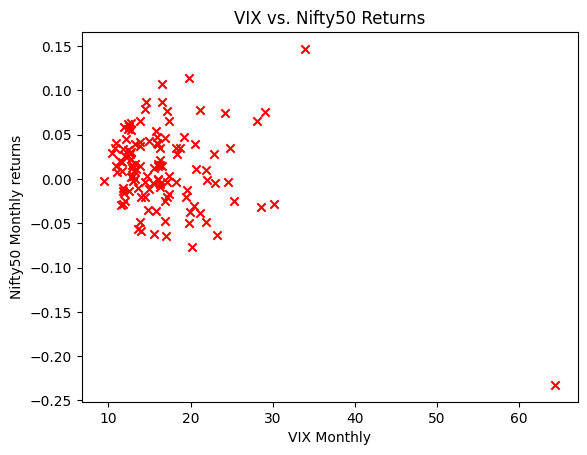

In [181]:
# visualise the data
plt.scatter(x_series, y_series, marker="x", c= "r")

plt.title("VIX vs. Nifty50 Returns")
plt.xlabel("VIX Monthly")
plt.ylabel("Nifty50 Monthly returns")


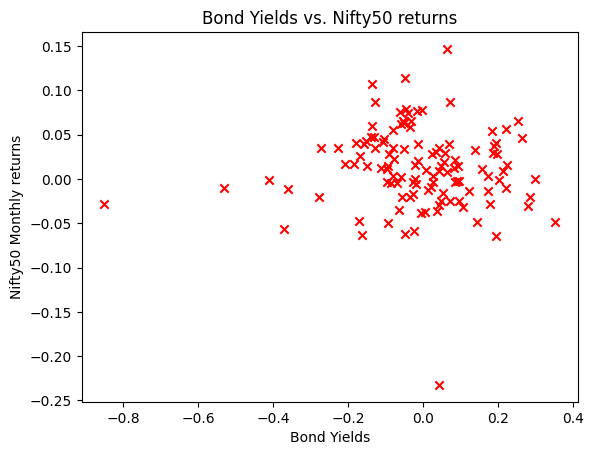

In [182]:
plt.scatter(x2_series, y_series, marker="x", c= "r")

plt.title("Bond Yields vs. Nifty50 returns")
plt.xlabel("Bond Yields")
plt.ylabel("Nifty50 Monthly returns")
plt.show()

In [183]:
# Get Numpy Arrays for the data

x_train = np.c_[x_series.to_numpy(), x2_series.to_numpy()]
y_train = y_series.to_numpy()

mask = ~np.isnan(x_train).any(axis=1)
x_train, y_train = x_train[mask], y_train[mask]

m = x_train.shape[0]

In [184]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler

In [185]:
# Z-Score Normalization

def zscore_normalize_features(X):
  mean = np.mean(X, axis= 0)
  std = np.std(X, axis= 0)

  X_norm =(X - mean) / std

  return X_norm

x_norm = zscore_normalize_features(x_train)


In [186]:
sgdr = SGDRegressor(max_iter =1000)
sgdr.fit(x_norm, y_train)

predictions = sgdr.predict(x_norm)

r2 = sgdr.score(x_norm, y_train)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


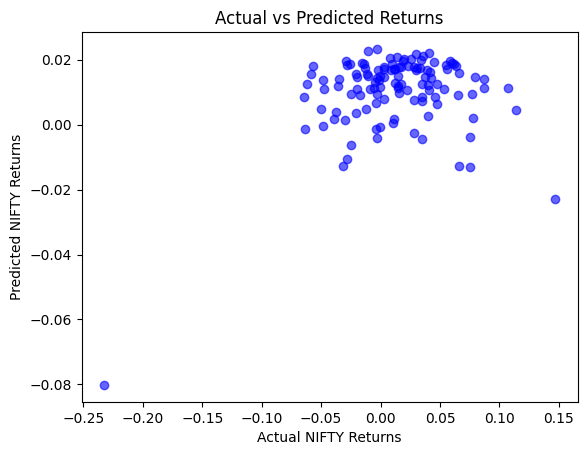

In [187]:
# Plotting y vs ŷ

plt.scatter(y_train, predictions, color="blue", alpha=0.6, marker="o")

plt.xlabel("Actual NIFTY Returns")
plt.ylabel("Predicted NIFTY Returns")
plt.title("Actual vs Predicted Returns")

plt.show()

In [188]:
print("Intercept:", sgdr.intercept_)
print("Coefficients:", sgdr.coef_)

Intercept: [0.01039224]
Coefficients: [-0.01201506 -0.00093957]


In [189]:
print(r2)

0.09020687676110617
